<h3><b><i>1: Instalações Bibliotecas necessárias</i></b></h3>
<pre>
Seaborn;
Streamlit;
Pandas.
</pre>

In [42]:
# !pip install seaborn streamlit pandas --quiet

<h3><b><i>2: ETL (Extração, Transformação e Carga dos dados)</i></b></h3>

In [43]:
import pandas as pd

# Carregamento dos dados
btc = pd.read_csv('/content/BTC.csv')
sol = pd.read_csv('/content/SOL.csv')
eth = pd.read_csv('/content/ETH.csv')
usdt = pd.read_csv('/content/USDT.csv')

# Conversão da coluna de datas para o formato datetime
btc['date'] = pd.to_datetime(btc['date'])
sol['date'] = pd.to_datetime(sol['date'])
eth['date'] = pd.to_datetime(eth['date'])
usdt['date'] = pd.to_datetime(usdt['date'])

# Inclusão de uma coluna 'coin' para identificar as moedas
btc['coin'] = 'BTC'
sol['coin'] = 'SOL'
eth['coin'] = 'ETH'
usdt['coin'] = 'USDT'

# Concatenar os dados de todas as moedas em um único DataFrame
df = pd.concat([btc, sol, eth, usdt])

# Ordenar os dados por data
df.sort_values('date', inplace=True)
df.reset_index(drop=True, inplace=True)

# Verificar valores ausentes
df.isnull().sum()

# Visualizar as primeiras linhas do DataFrame
df.head()

,ticker,date,open,high,low,close,coin
0,BTC,2010-07-17,0.04951,0.04951,0.04951,0.04951,BTC
1,BTC,2010-07-18,0.04951,0.08585,0.04951,0.08584,BTC
2,BTC,2010-07-19,0.08584,0.09307,0.07723,0.08080,BTC
3,BTC,2010-07-20,0.08080,0.08181,0.07426,0.07474,BTC
4,BTC,2010-07-21,0.07474,0.07921,0.06634,0.07921,BTC


In [44]:
# Estatísticas descritivas do DataFrame
df.describe()

,date,open,high,low,close
count,13495,13495.000000,13495.000000,13495.000000,13495.000000
mean,2019-11-05 14:45:46.083734528,6080.613520,6224.906723,5925.998645,6086.243108
min,2010-07-17 00:00:00,0.049510,0.049510,0.010000,0.049510
25%,2017-07-07 12:00:00,1.030000,1.090000,1.010000,1.030000
50%,2020-07-07 00:00:00,182.763000,189.085000,175.420000,183.005000
75%,2022-10-28 00:00:00,2567.550000,2643.775000,2480.330000,2568.080000
max,2025-04-06 00:00:00,105118.000000,106426.000000,103320.000000,105104.000000
std,NaN,15271.315146,15608.556450,14907.224473,15281.084141


In [45]:
# Verificar valores ausentes
df.isnull().sum()

,0
ticker,0
date,0
open,0
high,0
low,0
close,0
coin,0


In [46]:
# Verificar a distribuição das criptomoedas no dataset
df['coin'].value_counts()

,count
coin,
BTC,5330
ETH,3483
USDT,2907
SOL,1775


In [47]:
# Visualização do Dataframe
df

,ticker,date,open,high,low,close,coin
0,BTC,2010-07-17,0.04951,0.04951,0.04951,0.04951,BTC
1,BTC,2010-07-18,0.04951,0.08585,0.04951,0.08584,BTC
2,BTC,2010-07-19,0.08584,0.09307,0.07723,0.08080,BTC
3,BTC,2010-07-20,0.08080,0.08181,0.07426,0.07474,BTC
4,BTC,2010-07-21,0.07474,0.07921,0.06634,0.07921,BTC
...,...,...,...,...,...,...,...
13490,BTC,2025-04-05,84131.70000,84215.20000,82365.00000,82885.30000,BTC
13491,BTC,2025-04-06,82885.30000,83705.50000,78680.60000,78903.20000,BTC
13492,ETH,2025-04-06,1789.58000,1815.87000,1570.06000,1586.62000,ETH
13493,SOL,2025-04-06,118.90200,121.05200,106.05800,106.85600,SOL


<h3><b><i>3: Análise exploratória e visualizações iniciais com Seaborn</i></b></h3>

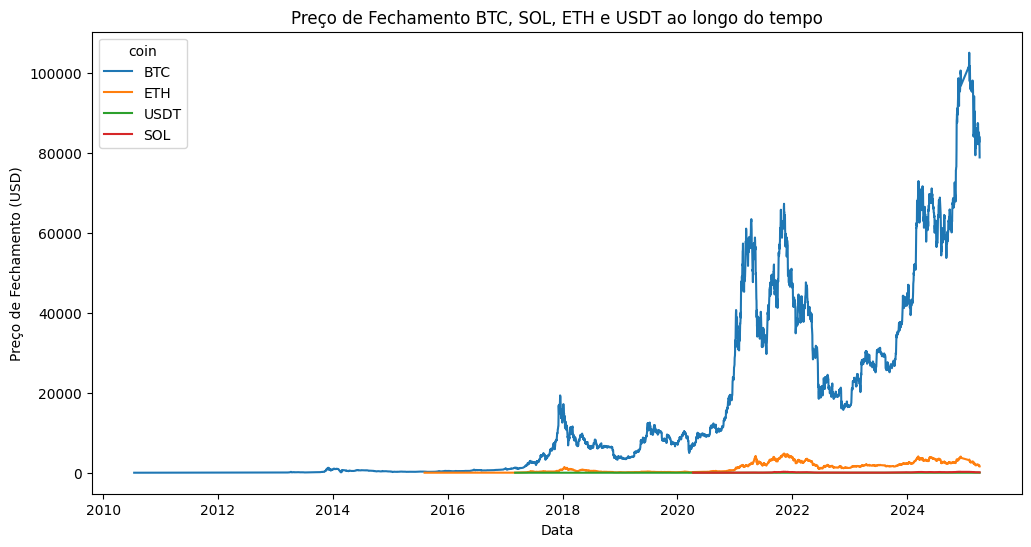

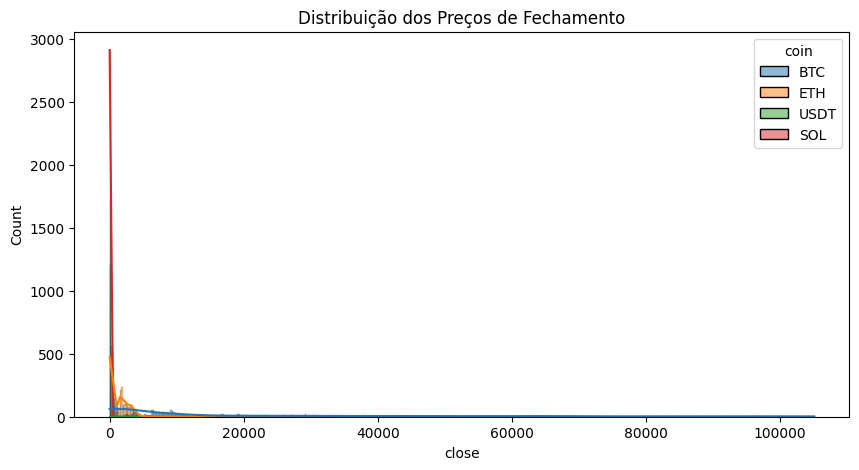

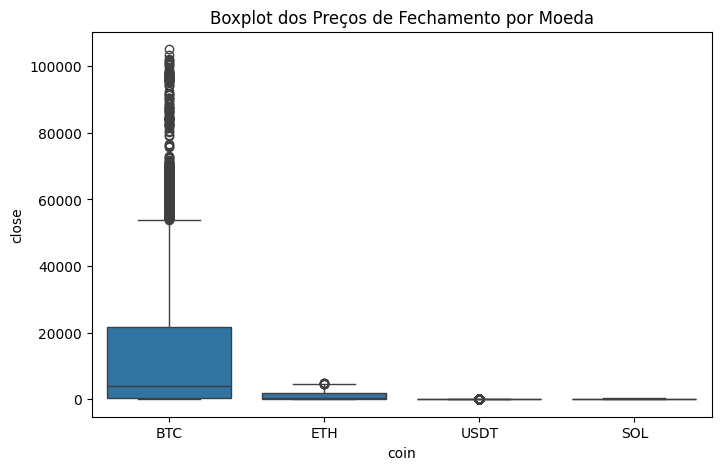

In [48]:
import seaborn as sns
import matplotlib.pyplot as plt

# Gráfico 1: Evolução do Preço de Fechamento ao longo do tempo
plt.figure(figsize=(12, 6))
sns.lineplot(data=df, x='date', y='close', hue='coin')
plt.title('Preço de Fechamento BTC, SOL, ETH e USDT ao longo do tempo')
plt.xlabel('Data')
plt.ylabel('Preço de Fechamento (USD)')
plt.show()

# Gráfico 2: Distribuição dos Preços de Fechamento (Histograma + KDE)
plt.figure(figsize=(10, 5))
sns.histplot(data=df, x='close', hue='coin', kde=True)
plt.title('Distribuição dos Preços de Fechamento')
plt.show()

# Gráfico 3: Boxplot para ver a dispersão dos preços
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='coin', y='close')
plt.title('Boxplot dos Preços de Fechamento por Moeda')
plt.show()

<h3><b><i>4: Aplicação interativa com Streamlit</i></b></h3>

In [49]:
import urllib
print("Endpoint IP:", urllib.request.urlopen('https://ipv4.icanhazip.com').read().decode('utf8').strip())

Endpoint IP: 34.169.106.203


In [50]:
!npm install -g localtunnel
!streamlit run app.py &>/content/logs.txt &
!npx localtunnel --port 8501

⠙⠹⠸⠼⠴⠦⠧
changed 22 packages in 983ms
⠧
⠧3 packages are looking for funding
⠧  run `npm fund` for details
⠧⠙⠹⠸⠼⠴your url is: https://tired-hotels-doubt.loca.lt
^C


---

### **Conclusão**

A análise exploratória das criptomoedas BTC, SOL, ETH e USDT revela uma série de padrões interessantes que podem ser úteis para investidores e analistas financeiros. Através da visualização dos dados, conseguimos identificar as tendências de **preço de fechamento** ao longo do tempo, **volatilidade diária** e outras métricas importantes para a análise de ativos financeiros.

#### **Insights dos Gráficos:**

- **Preço de Fechamento (Gráfico de Linha)**:
    A visualização das flutuações de preço ao longo do tempo ajuda a identificar períodos de forte crescimento ou queda. Isso pode ser crucial para observar momentos de alta ou baixa nos mercados.
  
- **Distribuição dos Preços (Histograma e KDE)**:
    A distribuição dos preços de fechamento nos permite entender a concentração de valores e identificar a **tendência central**. A presença de picos ou caudas longas pode indicar períodos de alta volatilidade.

- **Boxplot**:
    O boxplot ajuda a visualizar a **dispersão** dos preços, identificando facilmente outliers que podem representar dias com movimentos de preço atípicos, devido a fatores externos ou eventos significativos no mercado.

- **Volatilidade Diária**:
    A volatilidade foi fundamental para medir as **flutuações intradiárias** e detectar os dias de maior incerteza no mercado. Moedas com maior volatilidade são frequentemente associadas a riscos mais altos, mas também podem apresentar maiores oportunidades de ganho.

- **Média Móvel de 30 dias**:
    A média móvel suaviza as flutuações de preço e oferece uma visão mais clara das **tendências de longo prazo**. Esse gráfico é especialmente útil para identificar a direção geral do preço, ignorando as variações diárias.

#### **Análise Comparativa entre as Moedas**:
  
Através da seleção de diferentes moedas (BTC, SOL, ETH, USDT) e dos filtros por ano, conseguimos comparar o comportamento de cada uma delas em termos de preço e volatilidade, o que ajuda a entender o perfil de risco e retorno de cada criptomoeda.

O **Streamlit** permite uma análise dinâmica, onde o usuário pode explorar diferentes anos e observar como cada moeda se comportou em momentos específicos. Isso se traduz em um **canal de comunicação visual** poderoso para decisões de investimento, permitindo que os analistas identifiquem os momentos chave para entradas e saídas no mercado.

#### **Relevância das Visualizações de Dados:**

As visualizações criadas neste notebook oferecem **insights valiosos** para a análise de mercados financeiros. Elas ajudam os analistas a entender melhor o comportamento dos ativos e como fatores como volatilidade e tendência de preço influenciam as decisões do investidor.

Ao explorar essas visualizações interativas, conseguimos transformar dados complexos em **informações claras e acionáveis**, fundamentais para a tomada de decisões mais informadas no mercado financeiro.

---